<a href="https://colab.research.google.com/github/whitepail/m7_seminars/blob/main/%22%D0%A1%D0%B5%D0%BC%D0%B8%D0%BD%D0%B0%D1%80_4_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0%D0%B5%D0%BC_%D1%81_%D0%B4%D0%B0%D0%BD%D0%BD%D1%8B%D0%BC%D0%B8_%D0%B2_Python_(%D0%B4%D0%BB%D1%8F_%D1%81%D1%82%D1%83%D0%B4%D0%B5%D0%BD%D1%82%D0%BE%D0%B2)%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Блокнот для обучения Python

#### Первоначальная настройка среды Python. Загрузка тестовых файлов с прошлых семинаров

In [ ]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import math
%matplotlib inline

# If running in Google Colab, install PostgreSQL and restore the database
if 'google.colab' in sys.modules:
    # Download the robot tracks
    !wget -q -O robots_csv.zip https://getfile.dokpub.com/yandex/get/https://disk.yandex.ru/d/FsALwxu2C6_cJA
    !unzip -o /content/robots_csv.zip > /dev/null 2>&1

Зачитывание файла с координатами робота (GroupXXX_Robot.csv)

In [ ]:
# Создаем dict для хранения координат робота. Ключ - время, значение - список [x,y]
timecoords = ........

# Читаем файл GroupXXX_Robot.csv
with ........ as robot_file:
  # первая строка - header, ее пропускаем
  header = robot_file.________
  for .............
    # для каждой прочитанной строки - разбиваем ее на поля по точкам с запятой
    time,x,y,angle,speed,rotation = .................
    # print(f'{time} {x} {y} {angle} {speed} {rotation}') # если хотим проверить вывод

    # заполняем dict c координатами методом setdefault. Не забываем типизировать вводные данные по дороге
    timecoords.setdefault(..., (...,...,...))

# Выводим для отладки dict с коодинатами робота
print(timecoords);

{0: (0.0, 0.0, 75.0, 1.0, 0.0), 1: (0.258819045, 0.965925826, 75.0, 1.0, 0.0), 2: (0.51763809, 1.931851653, 75.0, 1.0, 0.0), 3: (0.776457135, 2.897777479, 75.0, 1.0, 0.0), 4: (1.03527618, 3.863703305, 75.0, 1.0, 0.0), 5: (1.294095226, 4.829629131, 75.0, 1.0, 0.0), 6: (1.552914271, 5.795554958, 75.0, 1.0, 0.0), 7: (1.811733316, 6.761480784, 75.0, 1.0, 0.0), 8: (2.070552361, 7.72740661, 75.0, 1.0, 0.0), 9: (2.329371406, 8.693332437, 75.0, 1.0, 0.0), 10: (2.588190451, 9.659258263, 75.0, 1.0, 0.0), 11: (2.847009496, 10.62518409, 75.0, 1.0, 0.0), 12: (3.105828541, 11.59110992, 75.0, 1.0, 0.0), 13: (3.364647586, 12.55703574, 75.0, 1.0, 0.0), 14: (3.623466631, 13.52296157, 75.0, 1.0, 0.0), 15: (3.882285677, 14.48888739, 75.0, 1.0, 0.0), 16: (4.141104722, 15.45481322, 75.0, 1.0, 0.0), 17: (4.399923767, 16.42073905, 75.0, 1.0, 0.0), 18: (4.658742812, 17.38666487, 75.0, 1.0, 0.0), 19: (4.917561857, 18.3525907, 75.0, 1.0, 0.0), 20: (5.176380902, 19.31851653, 75.0, 1.0, 0.0), 21: (5.435199947, 20.

#### Зачитывание файла с данными лидара (GroupXXX_Lidar.csv) и сразу же склеиваем с координатами робота

In [ ]:
#Создаем массив wall_x и wall_y
wall_x = []
wall_y = []

with ......:
  # первая строка - header, ее пропускаем
  header = lidar_file.readline()
  for ............
    # для каждой прочитанной строки - разбиваем ее на поля по точкам с запятой
    time,lidar_angle,lidar_length = ............
    time = ...(time) # типизируем сразу
    lidar_angle = ...
    lidar_length = ...

    # ищем координаты по времение в нашем словаре timecoords
    robot_x,robot_y,robot_angle,robot_speed,robot_rotation = ......
    #print(f'{time} {robot_x}, {robot_y}, {robot_angle}, {robot_speed}, {robot_rotation}, {lidar_angle}, {lidar_length}') # если хотим проверить вывод

    # заполняем списки wall_x и wall_y расчетными координатами (формула переехала из sql и excel без изменений)
    wall_x.append(robot_x+math.cos((robot_angle+lidar_angle)*math.pi/180)*lidar_length)
    wall_y.append(..........)

# проверяем для отладки
print(wall_x)
print(wall_y)

[-3.4118095480871022, -3.670628594023597, -3.929447639517569, -4.1882666843589, -4.44708572932117, -4.705904774727403, -4.964723819314554, -5.223542864154438, -5.482361909401751, -5.741180955077465, -6.0, -6.258819044960807, -6.517638088870342, -6.776457136526139, -7.035276178857011, -7.294095228740828, -6.29409522558214, -5.294095225323486, -5.294095225323486, -4.294095225597324, -3.294095221789776, -2.294095222838021, -1.2940952255126033, -0.29409522408223804, 0.7059047776937836, 1.705904772180865, 2.705904777158008, 3.705904774434308, 3.9647238171750363, 4.223542865941389, 4.482361908211203, 4.741180954707685, 5.0, 5.258819046045525, 5.51763809187813, 5.776457134678963, 6.035276180274732, 6.294095225582145, 6.552914266288972, 6.8117333186663815, 7.070552355620426, 7.329371412766969, 7.588190446432101, 4.611580850212681, 4.352761805612298, 4.093942758083441, 3.8351237146186583, 3.5763046681217343, 3.3174856228449308, 3.0586665799128974, 2.7998475339764024, 2.541028488482431, 2.282209

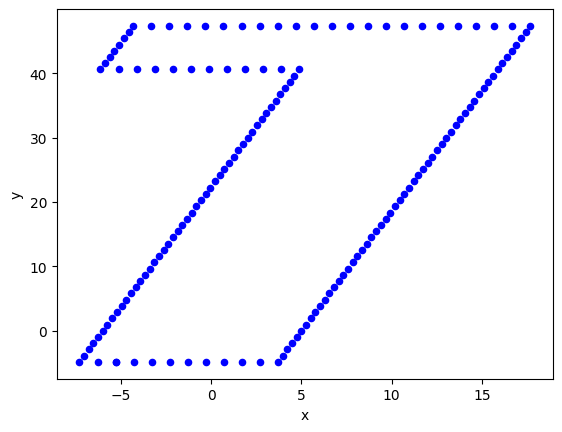

In [ ]:
# А теперь выведем на график план стен
df = pd.DataFrame({'x': wall_x, 'y': wall_y})
ax=df.plot(kind='scatter', x='x', y='y',color='blue')